# 3 · The Neural Riemannian Eikonal Solver (NES)

The grid solver of notebook 2 computes the distance *from one source*, and needs a grid — which
is impossible beyond a few dimensions.  NES learns the distance between **every pair** of points
of the space with a neural network,

$$U_\theta(q_s,q_e)\approx\text{geodesic distance between } q_s \text{ and } q_e ,$$

trained **without any ground-truth distances** — only by asking the network to satisfy the
eikonal equation.  Nothing in the network or the loss depends on the dimension or on what the
coordinates mean; we train it on the configuration space of the arm, and the paper uses the same
construction for a 7-joint arm.  In this notebook:

1. how the network is built so that it is a valid distance;
2. the physics-informed loss, and a short training run;
3. using the trained model: distance fields, geodesic flows and geodesics between any pairs;
4. why this is fast.

In [1]:
import time

import numpy as np
import torch
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 80

from geodf import metrics, rfm, nes, plotting as P
from geodf.robots import PlanarArm

torch.manual_seed(0)
pi = np.pi
arm = PlanarArm()
G = metrics.kinetic_energy(arm)
lo, hi = [-pi, -pi], [pi, pi]

## 1. A network that is a distance by construction

Three properties of a distance are built into the architecture:

* **symmetry** $U(q_s,q_e)=U(q_e,q_s)$: an MLP $u_\theta$ is evaluated on both orderings and
  averaged, $u^{sym}_\theta=\tfrac12\big(u_\theta(q_s,q_e)+u_\theta(q_e,q_s)\big)$;
* **zero on the diagonal and positive elsewhere**: the output is *factorised*,
  $$U_\theta(q_s,q_e)=\|q_e-q_s\|\;\sigma\!\big(u^{sym}_\theta(q_s,q_e)\big),$$
  with $\sigma$ = softplus.  The zero at $q_s=q_e$ comes from the factor, and the network
  only has to learn the ratio between the geodesic and the Euclidean distance, which stays
  bounded (between the square roots of the smallest and largest eigenvalues of $G$).  Close to
  $q_s$ this ratio depends on the *direction* from $q_s$; notebook 6 shows what to do when this
  dependence is extreme.

`nes.NES` implements exactly this (a 3×128 tanh MLP).

In [2]:
model = nes.NES(lo, hi, hidden=(128, 128, 128))
print(model)
a, b = torch.rand(4, 2) * 6 - 3, torch.rand(4, 2) * 6 - 3
print("U(a, b) =", model(a, b).detach().numpy().round(4))
print("U(b, a) =", model(b, a).detach().numpy().round(4), " (symmetric)")
print("U(a, a) =", model(a, a).detach().numpy().round(4), " (zero on the diagonal)")

NES(
  (mlp): MLP(
    (net): Sequential(
      (0): Linear(in_features=4, out_features=128, bias=True)
      (1): Tanh()
      (2): Linear(in_features=128, out_features=128, bias=True)
      (3): Tanh()
      (4): Linear(in_features=128, out_features=128, bias=True)
      (5): Tanh()
      (6): Linear(in_features=128, out_features=1, bias=True)
    )
  )
)
U(a, b) = [3.5808 3.4187 1.2095 1.2846]
U(b, a) = [3.5808 3.4187 1.2095 1.2846]  (symmetric)
U(a, a) = [0. 0. 0. 0.]  (zero on the diagonal)


## 2. Training from the eikonal equation alone

For a fixed source $q_s$, the distance must satisfy $\|\nabla_{q_e}U(q_s,q_e)\|_{G^{-1}(q_e)}=1$
(notebook 2).  So the loss for a batch of random pairs is simply

$$\mathcal L=\frac1N\sum_{n}\Big(\big\|\nabla_{q_e}U_\theta(q_s^n,q_e^n)\big\|_{G^{-1}(q_e^n)}-1\Big)^2 ,$$

where the gradient is obtained by automatic differentiation.  Pairs are drawn uniformly in
$[-\pi,\pi]^2\times[-\pi,\pi]^2$, a fresh batch at every step (no dataset is stored).

Here is a short training run (1 500 steps, ~15 s on a CPU) to see the loss go down:

In [3]:
demo = nes.NES(lo, hi, hidden=(128, 128, 128))
t = time.time()
demo_hist = nes.train(demo, nes.uniform_pair_sampler(lo, hi, 1024),
                      metric_inv=lambda q, w: torch.linalg.inv(G(q)), steps=1500, log_every=300)
print(f"{time.time() - t:.0f} s")

step      0  loss 4.22e-01  (0s)


step    300  loss 8.84e-03  (3s)


step    600  loss 2.82e-03  (5s)


step    900  loss 1.87e-03  (8s)


step   1200  loss 1.49e-03  (10s)


step   1499  loss 1.42e-03  (13s)
14 s


A full run uses 15 000 steps (~2 min on 4 CPU cores, faster on a GPU).  We load the
trained weights shipped in `checkpoints/`; set `RETRAIN = True` to train it yourself.

loaded checkpoints/nes_ke.pt (trained in 101s)


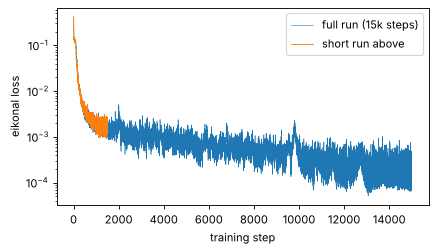

In [4]:
RETRAIN = False
model = nes.NES(lo, hi, hidden=(128, 128, 128))
history, train_time = nes.train_or_load(
    model, "checkpoints/nes_ke.pt",
    lambda: nes.train(model, nes.uniform_pair_sampler(lo, hi, 1024),
                      metric_inv=lambda q, w: torch.linalg.inv(G(q)), steps=15000, log_every=3000),
    retrain=RETRAIN)
model.eval()

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.semilogy(history, lw=0.5, label="full run (15k steps)")
ax.semilogy(demo_hist, lw=0.8, label="short run above")
ax.set_xlabel("training step"); ax.set_ylabel("eikonal loss"); ax.legend()
plt.show()

## 3. Using the trained model

### Distance field for one source
Fix $q_s$ and evaluate $U_\theta(q_s,\cdot)$ on a grid.  For reference we also solve the same
single-source problem with the grid solver of notebook 2.

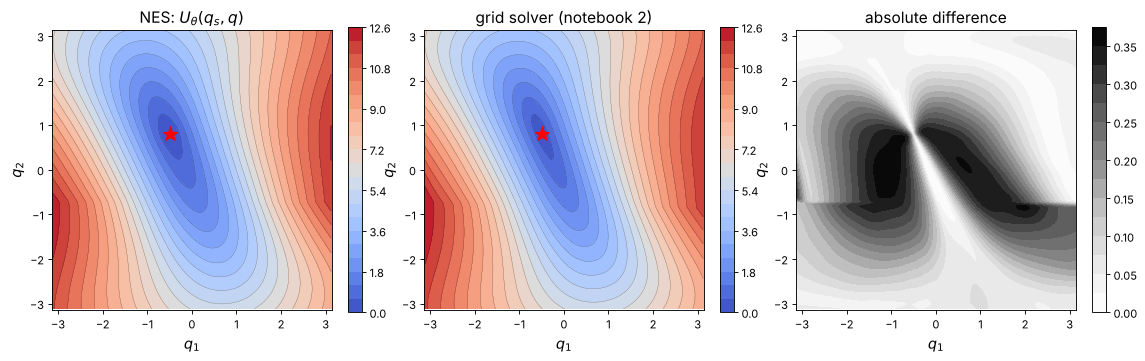

mean |U_NES - U_grid| = 0.141   (distances range up to 12.5)


In [5]:
q_s = np.array([-0.5, 0.8])
ref = rfm.solve(lambda q: G(q.double()), ((-pi, pi), (-pi, pi)), 150, q_s)
X, Y = ref.grid.X, ref.grid.Y
Q = torch.as_tensor(ref.grid.points.reshape(-1, 2), dtype=torch.float32)
S = torch.as_tensor(q_s, dtype=torch.float32).expand_as(Q)
U_nn, V_nn = nes.geodesic_flow(model, S, Q, G, normalize=False)
U_nn, V_nn = U_nn.numpy().reshape(X.shape), V_nn.numpy().reshape(X.shape + (2,))

fig, axs = plt.subplots(1, 3, figsize=(17, 5))
cf = P.field(axs[0], X, Y, U_nn)
fig.colorbar(cf, ax=axs[0], fraction=0.046)
axs[0].plot(*q_s, "r*", ms=14)
P.setup_ax(axs[0], title="NES: $U_\\theta(q_s, q)$")
cf = P.field(axs[1], X, Y, ref.U)
fig.colorbar(cf, ax=axs[1], fraction=0.046)
axs[1].plot(*q_s, "r*", ms=14)
P.setup_ax(axs[1], title="grid solver (notebook 2)")
cf = axs[2].contourf(X, Y, np.abs(U_nn - ref.U), 15, cmap="Greys")
fig.colorbar(cf, ax=axs[2], fraction=0.046)
P.setup_ax(axs[2], title="absolute difference")
plt.show()
print(f"mean |U_NES - U_grid| = {np.abs(U_nn - ref.U).mean():.3f}   (distances range up to {ref.U.max():.1f})")

The network has never seen a distance value, yet it reproduces the field of the grid solver
closely (the mean difference is about 2 % of the mean distance).  The difference map is
largest near lines where the true field has a **kink**, i.e. where two families of geodesics
meet (a cut locus, notebook 2) — for example the horizontal line at $q_2\approx-0.75$ (the metric only depends on $q_2$,
hence a horizontal line).  Both solvers have the kink, but a smooth network places and rounds
it slightly differently.

### Geodesic flow and geodesics
Exactly as in notebook 2, $V=G^{-1}\nabla_{q}U_\theta$ — now computed by autograd at any
point, not only on a grid.  `nes.backtrack` integrates $\dot q=-V/\|V\|_G$ for a batch of
starts at once.

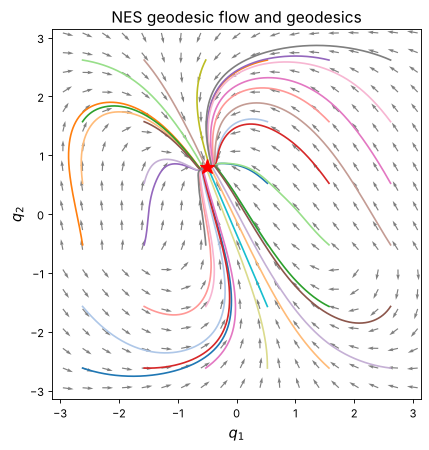

In [6]:
starts = np.array([[a, b] for a in -5 * pi / 6 + np.arange(6) * pi / 3 for b in -5 * pi / 6 + np.arange(6) * pi / 3])
starts = starts[np.linalg.norm(starts - q_s, axis=1) > 0.3]
src = torch.as_tensor(q_s, dtype=torch.float32).repeat(len(starts), 1)
paths = nes.backtrack(model, src, torch.as_tensor(starts, dtype=torch.float32), G, step=0.01, tol=0.03)

fig, ax = plt.subplots(figsize=(6, 6))
P.quiver(ax, X, Y, -V_nn, sub=8, color="gray")
for k, p in enumerate(paths):
    ax.plot(p[:, 0], p[:, 1], color=plt.get_cmap("tab20")(k % 20), lw=1.5)
ax.plot(*q_s, "r*", ms=14)
P.setup_ax(ax, title="NES geodesic flow and geodesics")
plt.show()

### Any source, any goal
The real benefit: the source is just an input.  Below, six random pairs are connected in both
directions ($a\to b$ solid, $b\to a$ dashed) without solving anything new.  The two directions
trace the same curve, as they should for a symmetric distance.

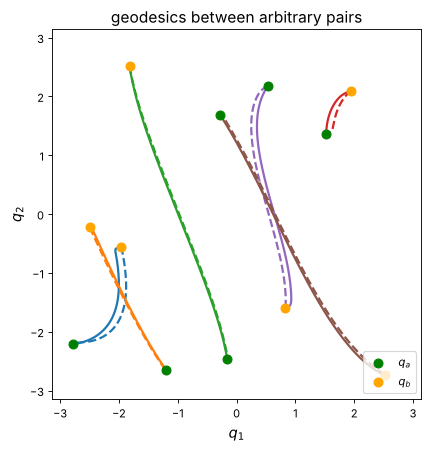

pair 0: U(a,b) = 5.064   U(b,a) = 5.064
pair 1: U(a,b) = 4.034   U(b,a) = 4.034
pair 2: U(a,b) = 7.138   U(b,a) = 7.138


In [7]:
g = torch.Generator().manual_seed(3)
A = (torch.rand(6, 2, generator=g) * 2 - 1) * 2.8
B = (torch.rand(6, 2, generator=g) * 2 - 1) * 2.8
a_to_b = nes.backtrack(model, B, A, G, step=0.01, tol=0.03)     # flow towards B, starting at A
b_to_a = nes.backtrack(model, A, B, G, step=0.01, tol=0.03)

fig, ax = plt.subplots(figsize=(6, 6))
for k in range(6):
    c = plt.get_cmap("tab10")(k)
    ax.plot(*a_to_b[k].T, "-", color=c, lw=2)
    ax.plot(*b_to_a[k].T, "--", color=c, lw=2)
ax.plot(*A.T, "o", color="green", ms=8, label="$q_a$")
ax.plot(*B.T, "o", color="orange", ms=8, label="$q_b$")
ax.legend(loc="lower right")
P.setup_ax(ax, title="geodesics between arbitrary pairs")
plt.show()
for k in range(3):
    print(f"pair {k}: U(a,b) = {model(A[k:k+1], B[k:k+1]).item():.3f}   U(b,a) = {model(B[k:k+1], A[k:k+1]).item():.3f}")

## 4. Why this is fast

Querying the distance and the geodesic direction is one forward and one backward pass of a
small MLP, and it is batched: thousands of (source, goal) pairs cost about as much as one.

In [8]:
for Bsz in [1, 100, 10_000]:
    qs = (torch.rand(Bsz, 2) * 2 - 1) * pi
    qe = (torch.rand(Bsz, 2) * 2 - 1) * pi
    nes.geodesic_flow(model, qs, qe, G)
    t = time.perf_counter()
    for _ in range(10):
        nes.geodesic_flow(model, qs, qe, G)
    print(f"{Bsz:6d} queries: {(time.perf_counter() - t) / 10 * 1e3:6.2f} ms")

     1 queries:   0.58 ms
   100 queries:   1.02 ms


 10000 queries:  25.07 ms


This makes the learned flow usable as a **feedback policy** at control rates — the topic of
notebook 5.  Notebook 4 first shows two extensions that come almost for free with a neural
representation: targets given in task space, and a family of metrics in one network.